In [ ]:
# CREATE ERROR CSV FILES

from astropy.io import fits
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

nights_folder = Path("E:/images")

nights = [
    night
    for night in nights_folder.iterdir()
    if "test" not in night.stem and "temp" not in night.stem and "TEST" not in night.stem
]
for night in nights[108:]:
    print(night)
    columns_headers = {
        "FILENAME": [],
        "DATE-OBS": [],
        "NCYCLES": [],
        "CYCLIND": [],
        "NSEQ": [],
        "SEQINDEX": [],
        "NFRAMES": [],
        "FRAMEIND": [],
        "EXPTIME": [],
        "WPPOS": [],
        "WPANG": [],
        "ERROR": [],
    }
    images = list(night.glob("*.fits"))

    for image in images:
        hdr = fits.getheader(image)
        if hdr["INSTMODE"] != "POLAR":
            continue
        if hdr["OBSTYPE"] != "OBJECT":
            continue
        if hdr["WPANG"] == "":
            continue
        if hdr["WPPOS"] == "":
            continue
        for key in columns_headers:
            if key == "ERROR":
                expected_ang = 22.5 * (hdr["WPPOS"] - 1)
                error = expected_ang - hdr["WPANG"]
                columns_headers["ERROR"].append(error)
            else:
                columns_headers[key].append(hdr[key])

    df = pd.DataFrame.from_dict(columns_headers)
    df = df[-300 < df["ERROR"]]
    csv_file = Path.cwd() / "_csv" / f"{night.stem}.csv"
    df.to_csv(csv_file, index=False)

In [ ]:
# FILTER 1 FRAME

import pandas as pd
from pathlib import Path


csv_folder = Path.cwd() / "_csv" / "raw"
for night in csv_folder.iterdir():
    df = pd.read_csv(night)
    df = df[df["FRAMEIND"] == 1]
    csv_file = Path.cwd() / "_csv" / "1_frame" / f"{night.stem}.csv"
    df.to_csv(csv_file, index=False)


In [ ]:
# FILTER CSVs

import pandas as pd
from pathlib import Path

headers = ["Date", "N. images", "Cycles"]
report = {k: [] for k in headers}

csv_folder = Path.cwd() / "_csv" / "1_frame"
for night in csv_folder.iterdir():
    report["Date"].append(night.stem)
    df = pd.read_csv(night)
    report["N. images"].append(df.shape[0])
    report["Cycles"].append(df["CYCLIND"].max())

report = pd.DataFrame.from_dict(report)
report = report.sort_values("Cycles", ascending=False)
report_file = Path.cwd() / "report.csv"
report.to_csv(report_file, index=False)
print(report.head(20))
print(report["Date"].head(20).values)


In [ ]:
# CREATE REPORT

import pandas as pd
from pathlib import Path

headers = ["Date", "N. images", "Cycles"]
report = {k: [] for k in headers}

csv_folder = Path.cwd() / "_csv" / "1_frame"
obs_nights = [
    "20260727",
    "20260728",
    "20260822",
    "20260731",
    "20260719",
    "20260713",
    "20260714",
    "20260823",
    "20260604",
    "20260816",
    "20260819",
    "20260809",
    "20260803",
    "20260715",
    "20260805",
    "20260702",
    "20260607",
    "20260606",
    "20260605",
    "20260815",
]
for night in obs_nights:
    report["Date"].append(night)
    df = pd.read_csv(csv_folder / f"{night}.csv")

    report["N. images"].append(df.shape[0])
    report["Cycles"].append(int(df["CYCLIND"].max()))

report = pd.DataFrame.from_dict(report)
report = report.sort_values("Date", ascending=True)
print(report["Date"].values)
report["Date"] = [f"{date[:4]}--{date[4:6]}--{date[6:]}" for date in report["Date"]]
print(report.to_latex(index=False))


In [ ]:
# PLOT HISTOGRAM DISTRIBUTIONS

import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
from pathlib import Path

fig, axs = plt.subplots(5, 4, figsize=(12, 12))
axs = axs.flatten()
font = 13


nights = [
    "20260604",
    "20260605",
    "20260606",
    "20260607",
    "20260702",
    "20260713",
    "20260714",
    "20260715",
    "20260719",
    "20260727",
    "20260728",
    "20260731",
    "20260803",
    "20260805",
    "20260809",
    "20260815",
    "20260816",
    "20260819",
    "20260822",
    "20260823",
]


for idx, night in enumerate(nights):
    ax = axs[idx]
    csv_file = Path.cwd() / "_csv" / "1_frame" / f"{night}.csv"
    df = pd.read_csv(csv_file)
    df = df[df["FRAMEIND"] == 1]
    mean = np.mean(df["ERROR"]) * 1e3
    std = np.std(df["ERROR"]) * 1e3
    ax.hist(df["ERROR"], color="blue", edgecolor="black", alpha=0.75)
    ax.set_title(rf"{night}", fontsize=font + 1)
    if idx % 4 == 0:
        ax.set_ylabel("Frequency", fontsize=font)
    if idx > 15:
        ax.set_xlabel("Error (deg)", fontsize=font)
    print(
        rf"{night} & {mean:.2f} & {std:.2f}\\",
    )


plt.tight_layout()
image_path = Path.cwd() / "_figs" / "wppos_error_hist.png"
plt.savefig(image_path, dpi=300, bbox_inches="tight")
image_path = Path(r"C:\Users\Denis\Desktop\NT_WPPOS_ERR\src\XX\Fig\error_histograms.png")
plt.savefig(image_path, dpi=300, bbox_inches="tight")
plt.show()

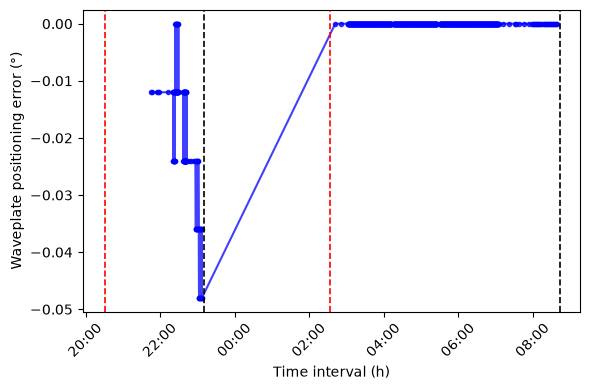

In [84]:
# ERROR TIME SERIES 20260606

import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
from pathlib import Path
from datetime import datetime
import matplotlib.dates as mdates

night = "20260606"
change_waveplate = [
    datetime.fromisoformat("2026-06-06T20:31:43.985Z"),
    datetime.fromisoformat("2026-06-07T02:32:47.130Z"),
]
phot_mode = [
    datetime.fromisoformat("2026-06-06T23:11:07.867Z"),
    datetime.fromisoformat("2026-06-07T08:43:47.641Z"),
]

fig, ax = plt.subplots(1, 1, sharey=True, figsize=(6, 4))
csv_file = Path.cwd() / "_csv" / "1_frame" / f"{night}.csv"
df = pd.read_csv(csv_file)
mean, std = np.mean(df["ERROR"]), np.std(df["ERROR"])
df["DATE-OBS"] = pd.to_datetime(df["DATE-OBS"], format="%Y-%m-%dT%H:%M:%S.%f")

ax.plot(df["DATE-OBS"], df["ERROR"], ".-b", alpha=0.75)
ax.set_ylabel("Waveplate positioning error (°)")
ax.set_xlabel("Time interval (h)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.tick_params(axis="x", labelrotation=45)
for event in change_waveplate:
    ax.axvline(event, color="red", linestyle="--", linewidth=1.2, alpha=1)  # type: ignore
for event in phot_mode:
    ax.axvline(event, color="k", linestyle="--", linewidth=1.2, alpha=1)  # type: ignore


image_path = Path.cwd() / "_figs" / f"{night}_err_time_series.png"
plt.savefig(image_path, dpi=300, bbox_inches="tight")
image_path = Path(
    rf"C:\Users\Denis\Desktop\NT_WPPOS_ERR\src\XX\Fig\{night}_err_time_series.png"
)
plt.savefig(image_path, dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [ ]:
# ERROR TIME SERIES 20260702

import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
from pathlib import Path
from datetime import datetime
import matplotlib.dates as mdates

night = "20260702"
change_waveplate = [
    datetime.fromisoformat("2026-07-02T20:07:00.277Z"),
    datetime.fromisoformat("2026-07-02T21:22:57.255Z"),
    datetime.fromisoformat("2026-07-02T22:37:23.683Z"),
    datetime.fromisoformat("2026-07-02T23:32:12.819Z"),
    datetime.fromisoformat("2026-07-02T23:54:15.504Z"),
    datetime.fromisoformat("2026-07-03T01:07:07.663Z"),
    datetime.fromisoformat("2026-07-03T01:38:50.965Z"),
    datetime.fromisoformat("2026-07-03T01:39:58.881Z"),
    datetime.fromisoformat("2026-07-03T05:48:22.556Z"),
    datetime.fromisoformat("2026-07-03T06:38:24.302Z"),
    datetime.fromisoformat("2026-07-03T06:42:05.403Z"),
    datetime.fromisoformat("2026-07-03T06:43:27.104Z"),
]
phot_mode = [
    datetime.fromisoformat("2026-07-02T23:59:05.375Z"),
    datetime.fromisoformat("2026-07-03T01:37:34.483Z"),
    datetime.fromisoformat("2026-07-03T05:47:20.317Z"),
    datetime.fromisoformat("2026-07-03T06:37:25.691Z"),
    datetime.fromisoformat("2026-07-03T08:36:08.211Z"),
]

fig, axs = plt.subplots(1, 2, sharey=True, figsize=(10, 4))
csv_file = Path.cwd() / "_csv" / "1_frame" / f"{night}.csv"
df = pd.read_csv(csv_file)
mean, std = np.mean(df["ERROR"]), np.std(df["ERROR"])
df["DATE-OBS"] = pd.to_datetime(df["DATE-OBS"], format="%Y-%m-%dT%H:%M:%S.%f")

ax = axs[0]
ax.plot(df["DATE-OBS"], df["ERROR"], "-b", alpha=0.75)
ax.set_ylabel("Waveplate positioning error (°)")
ax.set_xlabel("Time interval (h)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.tick_params(axis="x", labelrotation=45)
for event in change_waveplate:
    ax.axvline(event, color="red", linestyle="--", linewidth=1.2, alpha=1)  # type: ignore
for event in phot_mode:
    ax.axvline(event, color="k", linestyle="--", linewidth=1.2, alpha=1)  # type: ignore

df = df[df["SEQINDEX"] == 1]
df = df[df["DATE-OBS"] > datetime(2026, 7, 3, 1)]
df = df[df["DATE-OBS"] < datetime(2026, 7, 3, 5, 30)]
ax = axs[1]
ax.plot(df["DATE-OBS"], df["ERROR"], "o-b", alpha=0.75)
ax.set_xlabel("Time interval (h)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.tick_params(axis="x", labelrotation=45)


image_path = Path.cwd() / "_figs" / f"{night}_err_time_series.png"
plt.savefig(image_path, dpi=300, bbox_inches="tight")
image_path = Path(
    rf"C:\Users\Denis\Desktop\NT_WPPOS_ERR\src\XX\Fig\{night}_err_time_series.png"
)
plt.savefig(image_path, dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [ ]:
# ERROR TIME SERIES 20260714

import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
from pathlib import Path
from datetime import datetime
import matplotlib.dates as mdates

night = "20260714"
change_waveplate = [
    datetime.fromisoformat("2026-07-14T19:32:51.680Z"),
    datetime.fromisoformat("2026-07-14T19:46:51.757Z"),
    datetime.fromisoformat("2026-07-14T20:14:37.802Z"),
    datetime.fromisoformat("2026-07-14T20:30:28.969Z"),
    datetime.fromisoformat("2026-07-14T21:00:48.586Z"),
    datetime.fromisoformat("2026-07-14T21:03:26.458Z"),
    datetime.fromisoformat("2026-07-14T21:24:56.031Z"),
    datetime.fromisoformat("2026-07-15T01:41:01.551Z"),
]
phot_mode = [
    datetime.fromisoformat("2026-07-14T20:07:05.879Z"),
    datetime.fromisoformat("2026-07-14T20:29:23.313Z"),
    datetime.fromisoformat("2026-07-14T20:59:47.529Z"),
    datetime.fromisoformat("2026-07-14T21:02:17.512Z"),
    datetime.fromisoformat("2026-07-14T21:45:49.335Z"),
    datetime.fromisoformat("2026-07-15T08:51:11.263Z"),
]
fig, ax = plt.subplots(1, 1, sharey=True, figsize=(6, 4))
csv_file = Path.cwd() / "_csv" / "1_frame" / f"{night}.csv"
df = pd.read_csv(csv_file)
mean, std = np.mean(df["ERROR"]), np.std(df["ERROR"])
df["DATE-OBS"] = pd.to_datetime(df["DATE-OBS"], format="%Y-%m-%dT%H:%M:%S.%f")

ax.plot(df["DATE-OBS"], df["ERROR"], ".-b", alpha=0.5)
ax.set_ylabel("Waveplate positioning error (°)")
ax.set_xlabel("Time interval (h)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.tick_params(axis="x", labelrotation=45)
for event in change_waveplate:
    ax.axvline(event, color="red", linestyle="--", linewidth=1.2, alpha=1)  # type: ignore
for event in phot_mode:
    ax.axvline(event, color="k", linestyle="--", linewidth=1.2, alpha=1)  # type: ignore

image_path = Path.cwd() / "_figs" / f"{night}_err_time_series.png"
plt.savefig(image_path, dpi=300, bbox_inches="tight")
image_path = Path(
    rf"C:\Users\Denis\Desktop\NT_WPPOS_ERR\src\XX\Fig\{night}_err_time_series.png"
)
plt.savefig(image_path, dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [ ]:
# ERROR TIME SERIES 20260803

import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
from pathlib import Path
from datetime import datetime
import matplotlib.dates as mdates

night = "20260803"
change_waveplate = [
    datetime.fromisoformat("2026-08-03T19:12:12.767Z"),
    datetime.fromisoformat("2026-08-03T19:33:20.419Z"),
    datetime.fromisoformat("2026-08-03T21:27:47.263Z"),
    datetime.fromisoformat("2026-08-03T21:39:22.943Z"),
    datetime.fromisoformat("2026-08-04T00:15:22.838Z"),
    datetime.fromisoformat("2026-08-04T01:54:54.693Z"),
    datetime.fromisoformat("2026-08-04T03:37:42.609Z"),
    datetime.fromisoformat("2026-08-04T04:22:47.741Z"),
]
phot_mode = [
    datetime.fromisoformat("2026-08-04T04:15:26.739Z"),
    datetime.fromisoformat("2026-08-04T07:35:45.637Z"),
]
fig, ax = plt.subplots(1, 1, sharey=True, figsize=(6, 4))
csv_file = Path.cwd() / "_csv" / "1_frame" / f"{night}.csv"
df = pd.read_csv(csv_file)
mean, std = np.mean(df["ERROR"]), np.std(df["ERROR"])
df["DATE-OBS"] = pd.to_datetime(df["DATE-OBS"], format="%Y-%m-%dT%H:%M:%S.%f")

ax.plot(df["DATE-OBS"], df["ERROR"], ".-b", alpha=0.75)
ax.set_ylabel("Waveplate positioning error (°)")
ax.set_xlabel("Time interval (h)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.tick_params(axis="x", labelrotation=45)
for event in change_waveplate:
    ax.axvline(event, color="red", linestyle="--", linewidth=1.2)  # type: ignore
for event in phot_mode:
    ax.axvline(event, color="k", linestyle="--", linewidth=1.2)  # type: ignore

image_path = Path.cwd() / "_figs" / f"{night}_err_time_series.png"
plt.savefig(image_path, dpi=300, bbox_inches="tight")
image_path = Path(
    rf"C:\Users\Denis\Desktop\NT_WPPOS_ERR\src\XX\Fig\{night}_err_time_series.png"
)
plt.savefig(image_path, dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [ ]:
# ERROR TIME SERIES 20260809

import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
from pathlib import Path
from datetime import datetime
import matplotlib.dates as mdates

night = "20260809"
change_waveplate = [
    datetime.fromisoformat("2026-08-09T21:48:19.919Z"),
]
phot_mode = [
    datetime.fromisoformat("2026-08-10T01:22:06.980Z"),
]
fig, ax = plt.subplots(1, 1, sharey=True, figsize=(6, 4))
csv_file = Path.cwd() / "_csv" / "1_frame" / f"{night}.csv"
df = pd.read_csv(csv_file)
mean, std = np.mean(df["ERROR"]), np.std(df["ERROR"])
df["DATE-OBS"] = pd.to_datetime(df["DATE-OBS"], format="%Y-%m-%dT%H:%M:%S.%f")

ax.plot(df["DATE-OBS"], df["ERROR"], ".-b", alpha=0.5)
ax.set_ylabel("Waveplate positioning error (°)")
ax.set_xlabel("Time interval (h)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.tick_params(axis="x", labelrotation=45)
for event in change_waveplate:
    ax.axvline(event, color="red", linestyle="--", linewidth=1.2)  # type: ignore
for event in phot_mode:
    ax.axvline(event, color="k", linestyle="--", linewidth=1.2)  # type: ignore


image_path = Path.cwd() / "_figs" / f"{night}_err_time_series.png"
plt.savefig(image_path, dpi=300, bbox_inches="tight")
image_path = Path(
    rf"C:\Users\Denis\Desktop\NT_WPPOS_ERR\src\XX\Fig\{night}_err_time_series.png"
)
plt.savefig(image_path, dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [ ]:
# PLOT HISTOGRAM DISTRIBUTIONS

import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
from pathlib import Path


night = "20261114"
csv_file = Path.cwd() / "_csv" / f"{night}.csv"
df = pd.read_csv(csv_file)
plt.hist(df["error"], color="blue", edgecolor="black", alpha=0.75)
plt.xlabel("Waveplate positioning error (°)")
plt.ylabel("Frequency")

image_path = Path.cwd() / "_figs" / f"{night}_wppos_error_hist.png"
plt.savefig(image_path, dpi=300, bbox_inches="tight")
image_path = Path(
    rf"C:\Users\Denis\Desktop\NT_WPPOS_ERR\src\XX\Fig\{night}_error_histograms.png"
)
plt.savefig(image_path, dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# GET WPSEL COMMANDS

from pathlib import Path

night = "20260606"

log_file = Path.cwd() / "_logs" / f"{night}_s4ics.log"
with open(log_file) as file:
    lines = file.read().splitlines()

lines = [line for line in lines if "WPSEL GOTO" in line]
print(*lines, sep="\n")
for line in lines:
    if "OFF" not in line:
        timestamp = line.split("|")[0]
        print(f'datetime.fromisoformat("{timestamp}"),')

print("")
for line in lines:
    if "OFF" in line:
        timestamp = line.split("|")[0]
        print(f'datetime.fromisoformat("{timestamp}"),')